<a href="https://colab.research.google.com/github/Shaithra2107/HALT-RAG/blob/lift_signal/HALT_RAG_abstention_eval_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HALT-RAG: Abstention Evaluation (No Generator)

**Core question:** Can the Retrieval Lift Signal detect corpus coverage failure *before* generation?

**Evaluation logic:**
- `covered = 1` if gold answer appears in retrieved docs (system *should* generate)
- `covered = 0` if gold answer is absent from retrieved docs (system *should* abstain)
- Metric: Does lift score discriminate covered vs uncovered? → AUROC, F1, optimal threshold T*

No generator needed. No distilgpt2. Pure retrieval signal evaluation.

In [ ]:
# ── Install dependencies ──────────────────────────────────────────────────────
import subprocess, sys
pkgs = ['datasets', 'sentence-transformers', 'faiss-cpu', 'scikit-learn',
        'matplotlib', 'numpy', 'pandas', 'tqdm', 'transformers', 'torch']
for p in pkgs:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--break-system-packages', p], check=False)
print('Done')

Done


In [ ]:
# ── Imports ───────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
import pickle
import warnings
warnings.filterwarnings('ignore')

from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    f1_score, precision_score, recall_score,
    classification_report
)
from tqdm.auto import tqdm

print('Imports OK')

Imports OK


In [ ]:
# ── Config ────────────────────────────────────────────────────────────────────
TOP_K        = 5       # retrieved docs per query
N_RANDOM     = 50      # random samples for lift baseline
N_QUERIES    = 500     # queries to evaluate (increase if time allows)
SEED         = 42

# Strict 3-band RPDR methodology (exclude middle 50–500 band)
TAIL_MAX     = 50      # s_pop < 50  → tail (very rare)
HEAD_MIN     = 500     # s_pop > 500 → head (popular)

np.random.seed(SEED)
print('Config OK')

Config OK


In [ ]:
# ── Load corpus ───────────────────────────────────────────────────────────────
print('Loading corpus...')
corpus_ds = load_dataset('rag-datasets/rag-mini-wikipedia', 'text-corpus', split='passages')
corpus_texts = [row['passage'] for row in corpus_ds]
print(f'Corpus: {len(corpus_texts):,} passages')

Loading corpus...


README.md:   0%|          | 0.00/719 [00:00<?, ?B/s]

data/passages.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B /  797kB            

data/passages.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating passages split:   0%|          | 0/3200 [00:00<?, ? examples/s]

Corpus: 3,200 passages


In [ ]:
# ── Build Corpus Language Model (for Clarity Score) ──────────────────────────
# Clarity Score (Cronen-Townsend et al., 2002): KL divergence between
# the retrieved-doc LM and the full corpus LM.
# High clarity → retrieved docs use focused, specific vocabulary → good coverage.
from collections import Counter
import math

print('Building corpus language model...')
corpus_word_counts = Counter()
for text in corpus_texts:
    corpus_word_counts.update(text.lower().split())
total_corpus_words = sum(corpus_word_counts.values())
# Unigram probability for each word in corpus (used as background LM)
corpus_lm = {w: c / total_corpus_words for w, c in corpus_word_counts.items()}
print(f'Corpus LM: {len(corpus_lm):,} unique tokens')

Building corpus language model...
Corpus LM: 32,996 unique tokens


In [ ]:
# ── Signal 6: Max Sentence Similarity (MSS) — no extra model needed ───────────
# MSS splits each retrieved passage into sentences, computes cosine similarity
# between the query embedding and each sentence embedding (reusing the already-loaded
# all-MiniLM-L6-v2 embedder), and takes the MAX.
#
# Why MSS instead of a cross-encoder reranker?
#  - Fully domain-agnostic: no MS MARCO training assumption
#  - Zero extra model downloads: reuses `embedder` from cell-8
#  - Sentence-level granularity: one relevant sentence in a passage is enough
#    to indicate coverage, even if the full passage relevance is diluted
import re
print('Signal 6 = Max Sentence Similarity (MSS).')
print('Reuses the already-loaded all-MiniLM-L6-v2 embedder — no new model required.')


Signal 6 = Max Sentence Similarity (MSS).
Reuses the already-loaded all-MiniLM-L6-v2 embedder — no new model required.


In [ ]:
# ── Load PopQA (strict 3-band split) ─────────────────────────────────────────
print('Loading PopQA...')
popqa = load_dataset('akariasai/PopQA', split='test')
df = pd.DataFrame(popqa)

# Parse possible answers
import ast
def parse_answers(x):
    if isinstance(x, list): return [str(a).lower().strip() for a in x]
    try: return [str(a).lower().strip() for a in ast.literal_eval(x)]
    except: return [str(x).lower().strip()]

df['answers_parsed'] = df['possible_answers'].apply(parse_answers)
df['s_pop'] = pd.to_numeric(df['s_pop'], errors='coerce')
df = df.dropna(subset=['s_pop', 'question'])

# Strict 3-band — exclude middle
tail_df = df[df['s_pop'] < TAIL_MAX].copy()
head_df = df[df['s_pop'] > HEAD_MIN].copy()

# Sample balanced across bands
n_per_band = N_QUERIES // 2
tail_sample = tail_df.sample(min(n_per_band, len(tail_df)), random_state=SEED)
head_sample = head_df.sample(min(n_per_band, len(head_df)), random_state=SEED)
eval_df = pd.concat([tail_sample, head_sample]).reset_index(drop=True)

print(f'Tail queries: {len(tail_sample)} | Head queries: {len(head_sample)} | Total: {len(eval_df)}')

Loading PopQA...


Repo card metadata block was not found. Setting CardData to empty.


Tail queries: 250 | Head queries: 250 | Total: 500


In [ ]:
# ── Embed corpus ──────────────────────────────────────────────────────────────
print('Loading embedder...')
embedder = SentenceTransformer('all-MiniLM-L6-v2')

print('Embedding corpus (this takes ~30s)...')
corpus_embs = embedder.encode(corpus_texts, batch_size=256, show_progress_bar=True,
                               convert_to_numpy=True, normalize_embeddings=True)

# Build FAISS index (inner product = cosine since embeddings are normalised)
dim = corpus_embs.shape[1]
index = faiss.IndexFlatIP(dim)
index.add(corpus_embs.astype('float32'))
print(f'FAISS index built: {index.ntotal:,} vectors, dim={dim}')

Loading embedder...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding corpus (this takes ~30s)...


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

FAISS index built: 3,200 vectors, dim=384


In [ ]:
# ── Embed queries ─────────────────────────────────────────────────────────────
print('Embedding queries...')
query_texts = eval_df['question'].tolist()
query_embs = embedder.encode(query_texts, batch_size=256, show_progress_bar=True,
                              convert_to_numpy=True, normalize_embeddings=True)
print(f'Query embeddings: {query_embs.shape}')


Embedding queries...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Query embeddings: (500, 384)


In [ ]:
# ── Core evaluation loop ──────────────────────────────────────────────────────
import re
results = []

for i, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc='Evaluating'):
    q_emb = query_embs[eval_df.index.get_loc(i)].astype('float32').reshape(1, -1)
    q_emb_1d = query_embs[eval_df.index.get_loc(i)]  # 1-D for dot product with sentence embs
    answers = row['answers_parsed']
    band = 'tail' if row['s_pop'] < TAIL_MAX else 'head'

    # ── Retrieve top-k ────────────────────────────────────────────────────────
    sims, idxs = index.search(q_emb, TOP_K)
    ret_sims  = sims[0]
    ret_texts = [corpus_texts[j] for j in idxs[0]]

    # ── Coverage label (token overlap ≥ 0.5) ─────────────────────────────────
    combined_context = ' '.join(ret_texts).lower()
    context_tokens = set(combined_context.split())
    def token_overlap(ans):
        ans_tokens = set(ans.lower().split())
        if not ans_tokens: return 0.0
        return len(ans_tokens & context_tokens) / len(ans_tokens)
    covered = int(max(token_overlap(ans) for ans in answers) >= 0.5)

    # ── Random baseline ───────────────────────────────────────────────────────
    rand_idxs = np.random.choice(len(corpus_texts), N_RANDOM, replace=False)
    rand_embs = corpus_embs[rand_idxs].astype('float32')
    rand_sims = (rand_embs @ q_emb.T).flatten()

    mu_rand  = rand_sims.mean()
    sig_rand = rand_sims.std() + 1e-8
    mu_ret   = ret_sims.mean()

    # ── Signal 1: Lift (z-score) ──────────────────────────────────────────────
    lift = (mu_ret - mu_rand) / sig_rand

    # ── Signal 2: Relevance (mean cosine of top-k) ────────────────────────────
    relevance = float(mu_ret)

    # ── Signal 3: Inter-document consistency ──────────────────────────────────
    ret_embs = corpus_embs[idxs[0]].astype('float32')
    if TOP_K > 1:
        sim_matrix = ret_embs @ ret_embs.T
        mask = np.triu(np.ones_like(sim_matrix, dtype=bool), k=1)
        consistency = float(sim_matrix[mask].mean())
    else:
        consistency = 1.0

    # ── Signal 4: Keyword coverage ────────────────────────────────────────────
    stop = {'what','is','the','a','an','of','in','who','was','are','were','did','does','do',
            'has','have','had','when','where','how','why','which','that','this','it','its',
            'by','to','for','on','at','with','from','about','as','into','or','and','but'}
    q_words = set(row['question'].lower().split()) - stop
    kw_coverage = sum(1 for w in q_words if w in context_tokens) / len(q_words) if q_words else 0.0

    # ── Signal 5: Clarity Score (Cronen-Townsend et al., 2002) ───────────────
    ret_word_counts = Counter()
    for text in ret_texts:
        ret_word_counts.update(text.lower().split())
    total_ret_words = sum(ret_word_counts.values()) or 1
    clarity = 0.0
    for word, count in ret_word_counts.items():
        p_ret    = count / total_ret_words
        p_corpus = corpus_lm.get(word, 1e-10)
        clarity += p_ret * math.log(p_ret / p_corpus)
    clarity = max(clarity, 0.0)

    # ── Signal 6: Max Sentence Similarity (MSS) ───────────────────────────────
    # Split each retrieved passage into sentences, embed them with the same
    # all-MiniLM-L6-v2 embedder, take cosine sim with the query, and keep MAX.
    # Domain-agnostic: no trained task assumption, no new model.
    try:
        sentences = []
        for t in ret_texts:
            sents = re.split(r'(?<=[.!?])\s+', t.strip())
            sentences.extend([s for s in sents if len(s.split()) > 3])
        if sentences:
            s_embs = embedder.encode(sentences, normalize_embeddings=True,
                                     convert_to_numpy=True, show_progress_bar=False)
            sims_sent = s_embs @ q_emb_1d   # cosine (both normalised)
            max_sent_sim = float(sims_sent.max())
        else:
            max_sent_sim = float(relevance)  # fallback: passage-level relevance
    except Exception:
        max_sent_sim = 0.0

    results.append({
        'question'     : row['question'],
        's_pop'        : row['s_pop'],
        'band'         : band,
        'covered'      : covered,
        'lift'         : float(lift),
        'relevance'    : relevance,
        'consistency'  : consistency,
        'kw_coverage'  : kw_coverage,
        'clarity'      : clarity,
        'max_sent_sim' : max_sent_sim,
    })

res = pd.DataFrame(results)
print(f'\nDone. Coverage rate: {res.covered.mean():.1%} overall')
print(res.groupby('band')['covered'].mean().to_string())

Evaluating:   0%|          | 0/500 [00:00<?, ?it/s]


Done. Coverage rate: 20.4% overall
band
head    0.140
tail    0.268


In [ ]:
# ── RQ1: Signal-by-signal discrimination — 5-signal vs 6-signal ──────────────
print('=== RQ1: Individual Signal AUROC ===')
print()

all_6 = ['lift', 'relevance', 'consistency', 'kw_coverage', 'clarity', 'max_sent_sim']
set_5 = ['lift', 'relevance', 'kw_coverage', 'clarity', 'max_sent_sim']   # consistency dropped

print('--- 6-SIGNAL SET (all signals) ---')
for sig in all_6:
    auc   = roc_auc_score(res.covered, res[sig])
    cov   = res[res.covered==1][sig].mean()
    uncov = res[res.covered==0][sig].mean()
    print(f'{sig:<14}: AUROC={auc:.3f} | covered={cov:.4f} | uncovered={uncov:.4f} | gap={cov-uncov:.4f}')

print()
print('--- 5-SIGNAL SET (consistency dropped) ---')
for sig in set_5:
    auc   = roc_auc_score(res.covered, res[sig])
    cov   = res[res.covered==1][sig].mean()
    uncov = res[res.covered==0][sig].mean()
    print(f'{sig:<14}: AUROC={auc:.3f} | covered={cov:.4f} | uncovered={uncov:.4f} | gap={cov-uncov:.4f}')

print()
print('--- By band (6-signal) ---')
for band in ['tail', 'head']:
    sub = res[res.band==band]
    if sub.covered.nunique() < 2: continue
    print(f'\n{band}:')
    for sig in all_6:
        auc = roc_auc_score(sub.covered, sub[sig])
        print(f'  {sig:<14}: AUROC={auc:.3f}')

print()
print(f'Overall coverage — head: {res[res.band=="head"].covered.mean():.1%}, tail: {res[res.band=="tail"].covered.mean():.1%}')

=== RQ1: Individual Signal AUROC ===

--- 6-SIGNAL SET (all signals) ---
lift          : AUROC=0.598 | covered=4.0614 | uncovered=3.8761 | gap=0.1853
relevance     : AUROC=0.542 | covered=0.3827 | uncovered=0.3775 | gap=0.0053
consistency   : AUROC=0.516 | covered=0.3103 | uncovered=0.3095 | gap=0.0008
kw_coverage   : AUROC=0.610 | covered=0.1710 | uncovered=0.0962 | gap=0.0748
clarity       : AUROC=0.258 | covered=3.5209 | uncovered=4.1282 | gap=-0.6074
max_sent_sim  : AUROC=0.579 | covered=0.4389 | uncovered=0.4214 | gap=0.0174

--- 5-SIGNAL SET (consistency dropped) ---
lift          : AUROC=0.598 | covered=4.0614 | uncovered=3.8761 | gap=0.1853
relevance     : AUROC=0.542 | covered=0.3827 | uncovered=0.3775 | gap=0.0053
kw_coverage   : AUROC=0.610 | covered=0.1710 | uncovered=0.0962 | gap=0.0748
clarity       : AUROC=0.258 | covered=3.5209 | uncovered=4.1282 | gap=-0.6074
max_sent_sim  : AUROC=0.579 | covered=0.4389 | uncovered=0.4214 | gap=0.0174

--- By band (6-signal) ---

tail:

Optimal threshold T* = 3.4342
Best F1              = 0.371
AUROC (all)          = 0.598


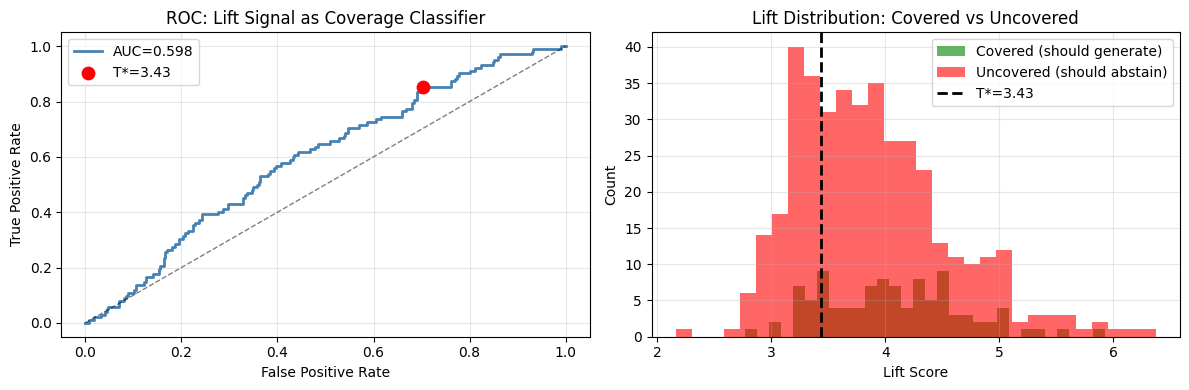

Plot saved as halt_rag_roc.png


In [ ]:
# ── ROC curve + optimal threshold T* ─────────────────────────────────────────
if res.covered.nunique() == 2:
    fpr, tpr, thresholds = roc_curve(res.covered, res.lift)
    auc_all = roc_auc_score(res.covered, res.lift)

    f1s = [f1_score(res.covered, (res.lift >= t).astype(int), zero_division=0) for t in thresholds]
    best_idx = int(np.argmax(f1s))
    T_star = float(thresholds[best_idx])
    best_f1 = f1s[best_idx]

    print(f'Optimal threshold T* = {T_star:.4f}')
    print(f'Best F1              = {best_f1:.3f}')
    print(f'AUROC (all)          = {auc_all:.3f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(fpr, tpr, color='steelblue', lw=2, label=f'AUC={auc_all:.3f}')
    axes[0].plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
    axes[0].scatter(fpr[best_idx], tpr[best_idx], color='red', zorder=5, s=80, label=f'T*={T_star:.2f}')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC: Lift Signal as Coverage Classifier')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].hist(res[res.covered==1]['lift'], bins=30, alpha=0.6, color='green', label='Covered (should generate)')
    axes[1].hist(res[res.covered==0]['lift'], bins=30, alpha=0.6, color='red', label='Uncovered (should abstain)')
    axes[1].axvline(T_star, color='black', lw=2, linestyle='--', label=f'T*={T_star:.2f}')
    axes[1].set_xlabel('Lift Score')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Lift Distribution: Covered vs Uncovered')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('./halt_rag_roc.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Plot saved as halt_rag_roc.png')
else:
    print('Only one class — cannot compute ROC.')
    T_star = res['lift'].median()
    best_f1 = 0.0
    auc_all = 0.5

In [ ]:
# ── RQ2: Abstention performance at T* ─────────────────────────────────────────
# lift >= T*  → generate (predict covered=1)
# lift < T*   → abstain  (predict covered=0)
print('=== RQ2: Abstention Performance at T* ===')
print()
preds = (res.lift >= T_star).astype(int)
print(classification_report(res.covered, preds, target_names=['Abstain','Generate'], digits=3))

print()
print('By band:')
for band in ['tail', 'head']:
    sub = res[res.band == band]
    p = (sub.lift >= T_star).astype(int)
    if sub.covered.nunique() < 2:
        print(f'  {band}: all queries {"covered" if sub.covered.iloc[0]==1 else "uncovered"}')
        continue
    f1  = f1_score(sub.covered, p, zero_division=0)
    prec = precision_score(sub.covered, p, zero_division=0)
    rec  = recall_score(sub.covered, p, zero_division=0)
    abstain_rate = (p==0).mean()
    print(f'  {band}: F1={f1:.3f} | Prec={prec:.3f} | Rec={rec:.3f} | Abstain rate={abstain_rate:.1%}')

=== RQ2: Abstention Performance at T* ===

              precision    recall  f1-score   support

     Abstain      0.887     0.296     0.444       398
    Generate      0.237     0.853     0.371       102

    accuracy                          0.410       500
   macro avg      0.562     0.575     0.408       500
weighted avg      0.755     0.410     0.429       500


By band:
  tail: F1=0.430 | Prec=0.293 | Rec=0.806 | Abstain rate=26.4%
  head: F1=0.303 | Prec=0.180 | Rec=0.943 | Abstain rate=26.8%


In [ ]:
# ── RQ3: Lift gap by band (the core HALT-RAG claim) ──────────────────────────
print('=== RQ3: Lift Gap head vs tail ===')
print()
for band in ['head', 'tail']:
    sub = res[res.band==band]
    print(f'{band}: n={len(sub)} | avg_lift={sub.lift.mean():.3f} | coverage={sub.covered.mean():.1%}')

print()
gap = res[res.band=='head']['lift'].mean() - res[res.band=='tail']['lift'].mean()
print(f'Lift gap (head - tail): {gap:.4f}')

from scipy import stats
head_lift = res[res.band=='head']['lift'].values
tail_lift = res[res.band=='tail']['lift'].values
t_stat, p_val = stats.ttest_ind(head_lift, tail_lift)
print(f't-test: t={t_stat:.3f}, p={p_val:.4f}')
print(f'Coverage gap (head - tail): {res[res.band=="head"].covered.mean() - res[res.band=="tail"].covered.mean():.1%}')

=== RQ3: Lift Gap head vs tail ===

head: n=250 | avg_lift=3.946 | coverage=14.0%
tail: n=250 | avg_lift=3.881 | coverage=26.8%

Lift gap (head - tail): 0.0648
t-test: t=1.102, p=0.2709
Coverage gap (head - tail): -12.8%


In [ ]:
# ── Save results ──────────────────────────────────────────────────────────────
output = {
    'results_df'  : res,
    'T_star'      : T_star,
    'best_f1'     : best_f1,
}
with open('./halt_rag_abstention_results.pkl', 'wb') as f:
    pickle.dump(output, f)

print('Results saved to halt_rag_abstention_results.pkl')
print()
print('=== SUMMARY ===')
print(f'Total queries evaluated : {len(res)}')
print(f'Overall coverage rate   : {res.covered.mean():.1%}')
print(f'Head coverage rate      : {res[res.band=="head"].covered.mean():.1%}')
print(f'Tail coverage rate      : {res[res.band=="tail"].covered.mean():.1%}')
if res.covered.nunique() == 2:
    print(f'AUROC (lift signal)     : {auc_all:.3f}')
    mss_auc = roc_auc_score(res.covered, res['max_sent_sim'])
    print(f'AUROC (max_sent_sim)    : {mss_auc:.3f}')
    kw_auc = roc_auc_score(res.covered, res['kw_coverage'])
    print(f'AUROC (kw_coverage)     : {kw_auc:.3f}')
print(f'Optimal threshold T*    : {T_star:.4f}')
print(f'Best abstention F1      : {best_f1:.3f}')
print(f'Lift gap (head - tail)  : {gap:.4f}')

# Clarity signal note
print()
print('=== CLARITY SIGNAL NOTE ===')
clarity_auc = roc_auc_score(res.covered, res['clarity'])
print(f'Clarity AUROC={clarity_auc:.3f} → inversely correlated with coverage')
print(f'  covered mean  : {res[res.covered==1]["clarity"].mean():.3f}  (lower)')
print(f'  uncovered mean: {res[res.covered==0]["clarity"].mean():.3f}  (higher)')
print(f'Negated clarity AUROC: {1-clarity_auc:.3f}')
print('Interpretation: uncovered queries retrieve off-topic but specific docs (high KL from corpus).')
print('For SWL: network will learn a negative weight for clarity automatically.')


Results saved to halt_rag_abstention_results.pkl

=== SUMMARY ===
Total queries evaluated : 500
Overall coverage rate   : 20.4%
Head coverage rate      : 14.0%
Tail coverage rate      : 26.8%
AUROC (lift signal)     : 0.598
AUROC (max_sent_sim)    : 0.579
AUROC (kw_coverage)     : 0.610
Optimal threshold T*    : 3.4342
Best abstention F1      : 0.371
Lift gap (head - tail)  : 0.0648

=== CLARITY SIGNAL NOTE ===
Clarity AUROC=0.258 → inversely correlated with coverage
  covered mean  : 3.521  (lower)
  uncovered mean: 4.128  (higher)
Negated clarity AUROC: 0.742
Interpretation: uncovered queries retrieve off-topic but specific docs (high KL from corpus).
For SWL: network will learn a negative weight for clarity automatically.
